# Raw Model

## Setup

In [5]:
import random

import seaborn as sns
import matplotlib.pyplot as plt

import torch
from numpy.typing import NDArray

if torch.backends.mps.is_available():
    torch.set_default_device("mps")
    print("MPS device found!")


SEED = random.SystemRandom().randint(0, 2**32 - 1)
torch.manual_seed(SEED)
print(f"Random seed: {SEED}")

def to_numpy(tensor: torch.Tensor) -> NDArray:
    return tensor.detach().cpu().numpy().squeeze()

MPS device found!
Random seed: 1069837278


## Full-Batch Gradient Descent

Epoch 00: Loss=6.5105, W=-0.303, b=0.224
Epoch 10: Loss=5.3370, W=0.022, b=0.322
Epoch 20: Loss=4.4209, W=0.308, b=0.411
Epoch 30: Loss=3.7054, W=0.561, b=0.492
Epoch 40: Loss=3.1466, W=0.783, b=0.564
Epoch 50: Loss=2.7100, W=0.979, b=0.630
Epoch 60: Loss=2.3688, W=1.152, b=0.689
Epoch 70: Loss=2.1022, W=1.305, b=0.742
Epoch 80: Loss=1.8939, W=1.440, b=0.789
Epoch 90: Loss=1.7310, W=1.559, b=0.831


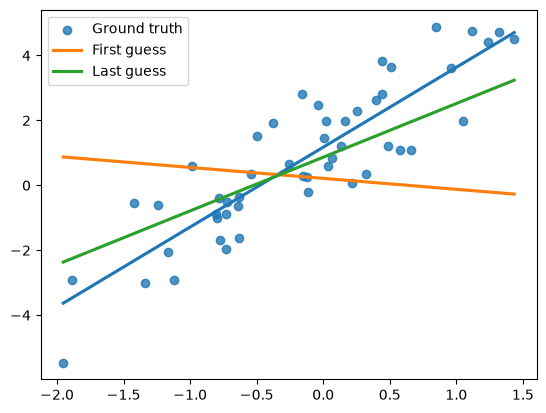

In [6]:
fig, ax = plt.subplots()

def add_to_plot(X: torch.Tensor, Y: torch.Tensor, label: str, isShowMarkers: bool = True):
    sns.regplot(
        x=to_numpy(X),
        y=to_numpy(Y),
        ax=ax,
        ci=None,
        scatter=isShowMarkers,
        label=label
    )

N = 50
D_x = 1
D_y = 1
X = torch.randn(N, D_x)

# True data generator
true_W = torch.tensor([[2.0]])
true_b = torch.tensor([[1]])
y_true = X @ true_W + true_b + 1.0*torch.randn(N, D_y)

# Model
W, b = torch.randn(D_x, D_y, requires_grad=True), torch.randn(1, D_y, requires_grad=True)
learning_rate, epochs = 0.01, 100

add_to_plot(X, y_true, "Ground truth")

# Forward pass
y_hat = X@W+b

add_to_plot(X, y_hat, "First guess", False)

for epoch in range(epochs):

    loss = torch.mean((y_hat - y_true) ** 2)

    # Backwards pass: compute gradients
    loss.backward()

    # Update params
    with torch.no_grad():
        W -= learning_rate * W.grad; b-= learning_rate * b.grad

    # Zero gradients
    W.grad.zero_(); b.grad.zero_()

    if epoch % 10 == 0:
        print(f"Epoch {epoch:02d}: Loss={loss.item():.4f}, W={W.item():.3f}, b={b.item():.3f}")

    # Forward pass
    y_hat = X@W+b



add_to_plot(X, y_hat, "Last guess", False)

ax.legend()
plt.show()